In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np

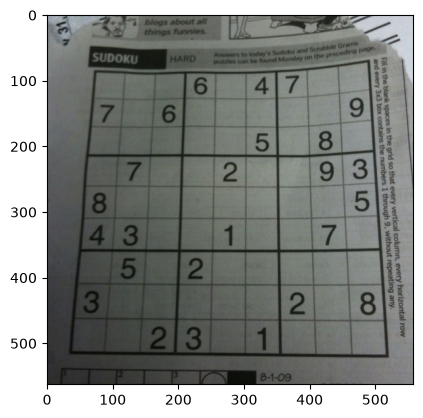

In [2]:
img = cv2.imread("sudoku.png", cv2.IMREAD_COLOR_RGB)
img.shape

plt.imshow(img)
plt.show()

In [3]:
def apply_perspective_transform(image, src_pts, dst_pts, size):
    M = cv2.getPerspectiveTransform(src_pts, dst_pts)
    return cv2.warpPerspective(image, M, size), M


# inverse
width, height = 500, 500
tilted = np.float32([[73, 84], [492, 69], [520, 522], [34, 516]])
rect = np.float32([[0, 0], [width, 0], [width, height], [0, height]])

flat, M = apply_perspective_transform(img, tilted, rect, (width, height))
M

array([[ 1.30587882e+00,  1.17891838e-01, -1.05232069e+02],
       [ 5.01004951e-02,  1.39947383e+00, -1.21213138e+02],
       [ 1.29951153e-04,  3.89184519e-04,  1.00000000e+00]])

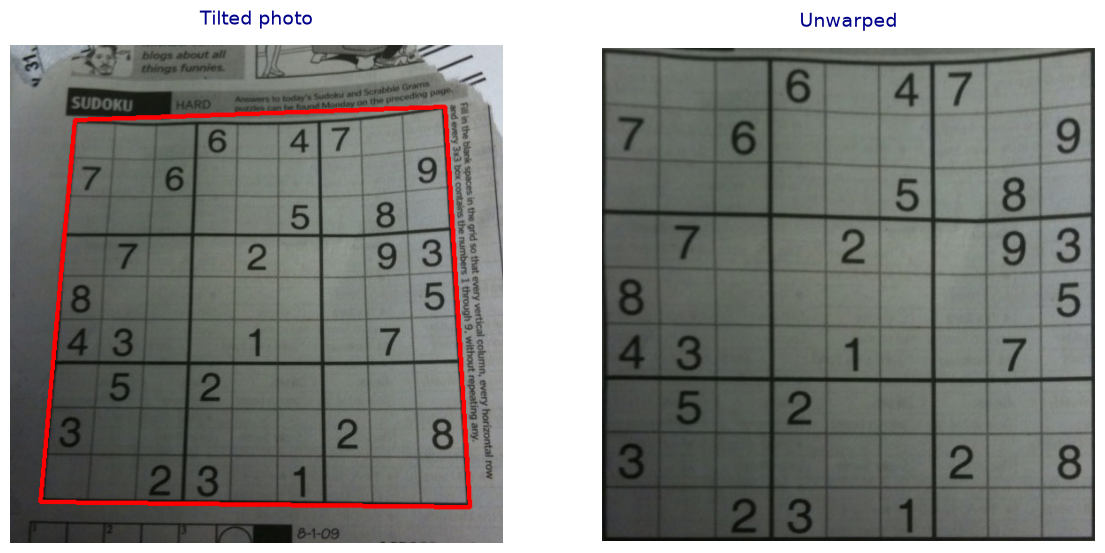

In [4]:
marked = img.copy()
cv2.polylines(marked, [tilted.astype(np.int32)], True, (255, 0, 0), 3)

panels = [('Tilted photo', marked), ('Unwarped', flat)]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes = axes.flatten()

for ax, (title, im) in zip(axes, panels):
    ax.imshow(im)
    ax.axis('off')
    ax.set_title(title, fontsize=14, color='darkblue', pad=15)

plt.show()

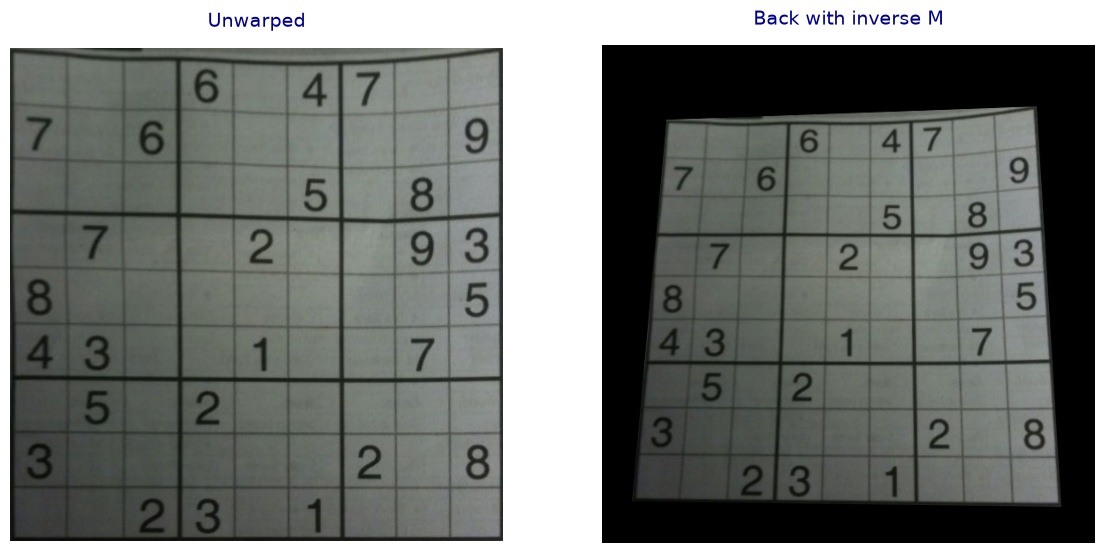

In [5]:
# back with inverse
back = cv2.warpPerspective(flat, np.linalg.inv(M), (img.shape[1], img.shape[0]))

panels = [('Unwarped', flat), ('Back with inverse M', back)]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes = axes.flatten()

for ax, (title, im) in zip(axes, panels):
    ax.imshow(im)
    ax.axis('off')
    ax.set_title(title, fontsize=14, color='darkblue', pad=15)

plt.show()

In [6]:
os.makedirs('output', exist_ok=True)
cv2.imwrite('output/task2_unwarped.png', cv2.cvtColor(flat, cv2.COLOR_RGB2BGR))

True